In [12]:
import pandas as pd

dataset = pd.read_csv('data/AmesHousing.csv' , sep = '\t', keep_default_na = False, na_values = [''])
display(dataset.head())
dataset.info()

,Order,PID,MS SubClass,MS Zoning,Lot Frontage,Lot Area,Street,Alley,Lot Shape,Land Contour,...,Pool Area,Pool QC,Fence,Misc Feature,Misc Val,Mo Sold,Yr Sold,Sale Type,Sale Condition,SalePrice
0,1,526301100,20,RL,141.0,31770,Pave,NA,IR1,Lvl,...,0,NA,NA,NA,0,5,2010,WD,Normal,215000
1,2,526350040,20,RH,80.0,11622,Pave,NA,Reg,Lvl,...,0,NA,MnPrv,NA,0,6,2010,WD,Normal,105000
2,3,526351010,20,RL,81.0,14267,Pave,NA,IR1,Lvl,...,0,NA,NA,Gar2,12500,6,2010,WD,Normal,172000
3,4,526353030,20,RL,93.0,11160,Pave,NA,Reg,Lvl,...,0,NA,NA,NA,0,4,2010,WD,Normal,244000
4,5,527105010,60,RL,74.0,13830,Pave,NA,IR1,Lvl,...,0,NA,MnPrv,NA,0,3,2010,WD,Normal,189900


<class 'pandas.DataFrame'>
RangeIndex: 2930 entries, 0 to 2929
Data columns (total 82 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order            2930 non-null   int64  
 1   PID              2930 non-null   int64  
 2   MS SubClass      2930 non-null   int64  
 3   MS Zoning        2930 non-null   str    
 4   Lot Frontage     2440 non-null   float64
 5   Lot Area         2930 non-null   int64  
 6   Street           2930 non-null   str    
 7   Alley            2930 non-null   str    
 8   Lot Shape        2930 non-null   str    
 9   Land Contour     2930 non-null   str    
 10  Utilities        2930 non-null   str    
 11  Lot Config       2930 non-null   str    
 12  Land Slope       2930 non-null   str    
 13  Neighborhood     2930 non-null   str    
 14  Condition 1      2930 non-null   str    
 15  Condition 2      2930 non-null   str    
 16  Bldg Type        2930 non-null   str    
 17  House Style      2930 non

# Fidnding real missing values 


In [13]:
# Folgende Funktionen aus Pandas oder Matplotlib könnten nutzlich sein: 
# isnull, isna, value_counts, describe, head, mean, min, 
# max, groupby, scatter, hist, corr...


missing_data = dataset.isnull().sum()
print("Collumns with missing values: ")
print(missing_data[missing_data>0])



Collumns with missing values: 
Lot Frontage      490
Mas Vnr Type       23
Mas Vnr Area       23
Bsmt Qual           1
Bsmt Cond           1
Bsmt Exposure       4
BsmtFin Type 1      1
BsmtFin SF 1        1
BsmtFin Type 2      2
BsmtFin SF 2        1
Bsmt Unf SF         1
Total Bsmt SF       1
Electrical          1
Bsmt Full Bath      2
Bsmt Half Bath      2
Garage Yr Blt     159
Garage Finish       2
Garage Cars         1
Garage Area         1
Garage Qual         1
Garage Cond         1
dtype: int64


# Bar chart to see missing values more clearly
### for some columns, 'NA' and 'NaN' mean that the feature does not exist, not that it was a missig value. And so, i did a bar chart to see more clearly the real missing values.

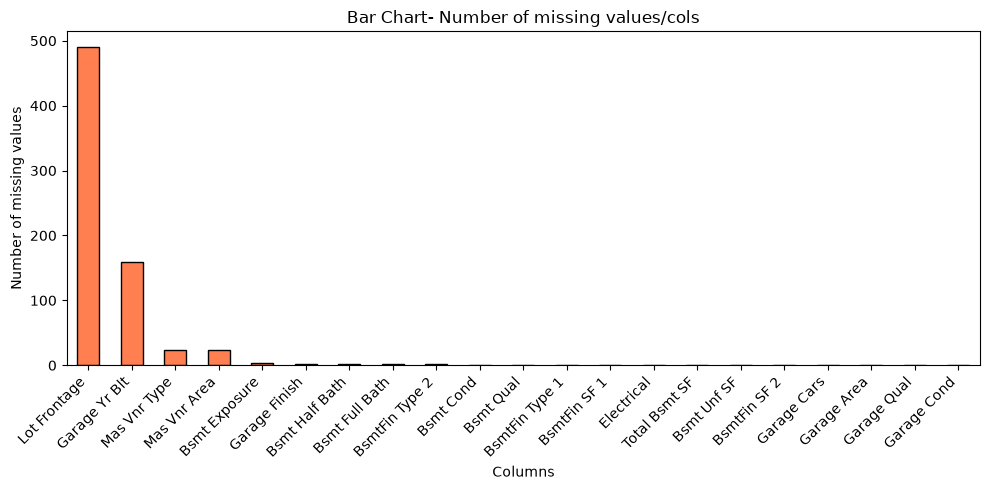

In [14]:
import matplotlib.pyplot as plt
missing_data = dataset.isnull().sum()
missing_data = missing_data[missing_data > 0].sort_values(ascending=False)

plt.figure(figsize=(10, 5))
missing_data.plot(kind='bar', color='coral', edgecolor='black')
plt.title('Bar Chart- Number of missing values/cols')
plt.xlabel('Columns')
plt.ylabel('Number of missing values')
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

**Interpretation**

- `Lot Frontage` has by far the most missing values (490, 16.7%). These are real missing values and would need to be imputed (e.g. with the median of the same neighborhood) or the feature removed.
- `Garage Yr Blt` has 159 missing values, but 157 of them are houses **without a garage**, so a year cannot exist. Only 2 are real missing values.
- All other columns have at most 23 missing values (< 1%).

# Separate numerical from categorical
### it is useful because depending on the type of the column, you know wich type of chart to use. 

### for example for numeric you can do histogram, scatter and for categorical, bar chart or compare groups. Median has no sense for categorical.

In [15]:
numeric_cols = dataset.select_dtypes(include = "number").columns
categoricat_cols = dataset.select_dtypes(exclude="number").columns
print (len(numeric_cols), "numerical= ", numeric_cols)
print(len(categoricat_cols), "categorical= ", categoricat_cols)

39 numerical=  Index(['Order', 'PID', 'MS SubClass', 'Lot Frontage', 'Lot Area',
       'Overall Qual', 'Overall Cond', 'Year Built', 'Year Remod/Add',
       'Mas Vnr Area', 'BsmtFin SF 1', 'BsmtFin SF 2', 'Bsmt Unf SF',
       'Total Bsmt SF', '1st Flr SF', '2nd Flr SF', 'Low Qual Fin SF',
       'Gr Liv Area', 'Bsmt Full Bath', 'Bsmt Half Bath', 'Full Bath',
       'Half Bath', 'Bedroom AbvGr', 'Kitchen AbvGr', 'TotRms AbvGrd',
       'Fireplaces', 'Garage Yr Blt', 'Garage Cars', 'Garage Area',
       'Wood Deck SF', 'Open Porch SF', 'Enclosed Porch', '3Ssn Porch',
       'Screen Porch', 'Pool Area', 'Misc Val', 'Mo Sold', 'Yr Sold',
       'SalePrice'],
      dtype='str')
43 categorical=  Index(['MS Zoning', 'Street', 'Alley', 'Lot Shape', 'Land Contour',
       'Utilities', 'Lot Config', 'Land Slope', 'Neighborhood', 'Condition 1',
       'Condition 2', 'Bldg Type', 'House Style', 'Roof Style', 'Roof Matl',
       'Exterior 1st', 'Exterior 2nd', 'Mas Vnr Type', 'Exter Qual',
     

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns
display(dataset.describe())

,Order,PID,MS SubClass,Lot Frontage,Lot Area,Overall Qual,Overall Cond,Year Built,Year Remod/Add,Mas Vnr Area,...,Wood Deck SF,Open Porch SF,Enclosed Porch,3Ssn Porch,Screen Porch,Pool Area,Misc Val,Mo Sold,Yr Sold,SalePrice
count,2930.00000,2.930000e+03,2930.000000,2440.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2907.000000,...,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000,2930.000000
mean,1465.50000,7.144645e+08,57.387372,69.224590,10147.921843,6.094881,5.563140,1971.356314,1984.266553,101.896801,...,93.751877,47.533447,23.011604,2.592491,16.002048,2.243345,50.635154,6.216041,2007.790444,180796.060068
std,845.96247,1.887308e+08,42.638025,23.365335,7880.017759,1.411026,1.111537,30.245361,20.860286,179.112611,...,126.361562,67.483400,64.139059,25.141331,56.087370,35.597181,566.344288,2.714492,1.316613,79886.692357
min,1.00000,5.263011e+08,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,12789.000000
25%,733.25000,5.284770e+08,20.000000,58.000000,7440.250000,5.000000,5.000000,1954.000000,1965.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4.000000,2007.000000,129500.000000
50%,1465.50000,5.354536e+08,50.000000,68.000000,9436.500000,6.000000,5.000000,1973.000000,1993.000000,0.000000,...,0.000000,27.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,160000.000000
75%,2197.75000,9.071811e+08,70.000000,80.000000,11555.250000,7.000000,6.000000,2001.000000,2004.000000,164.000000,...,168.000000,70.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,213500.000000
max,2930.00000,1.007100e+09,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,...,1424.000000,742.000000,1012.000000,508.000000,576.000000,800.000000,17000.000000,12.000000,2010.000000,755000.000000


# Histogram for SalePrice
### to help us see how are the prices, what is the "basic/average" price for most houses.

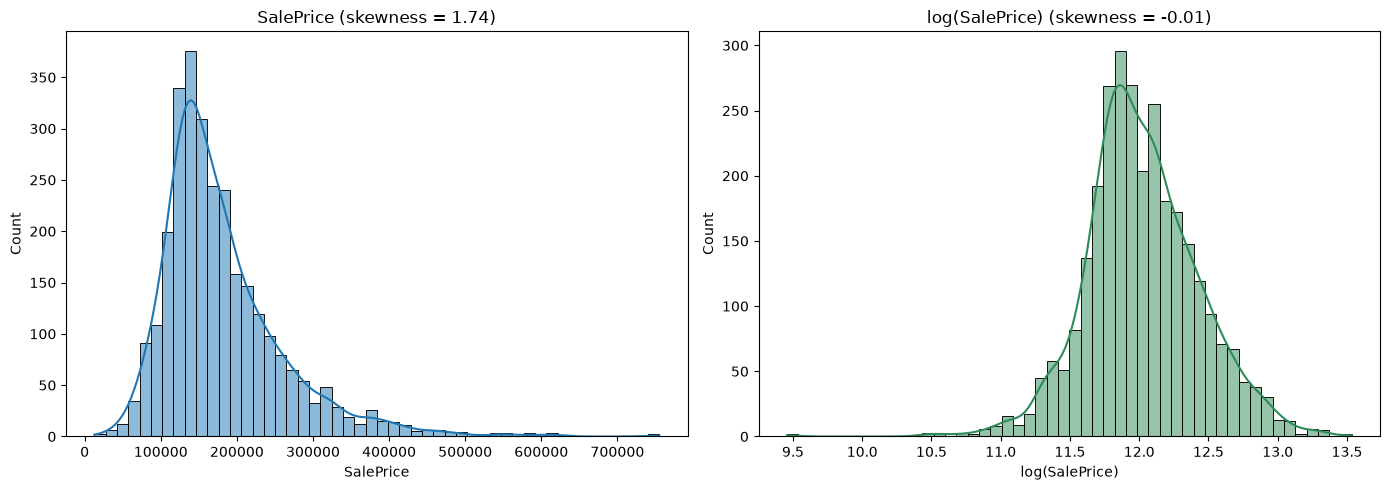

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Original prices
sns.histplot(dataset["SalePrice"], bins=50, kde=True, ax=axes[0])
axes[0].set_title(f"SalePrice (skewness = {dataset['SalePrice'].skew():.2f})")

# Log-transformed prices
sns.histplot(np.log(dataset["SalePrice"]), bins=50, kde=True, ax=axes[1], color="seagreen")
axes[1].set_title(f"log(SalePrice) (skewness = {np.log(dataset['SalePrice']).skew():.2f})")
axes[1].set_xlabel("log(SalePrice)")

plt.tight_layout()
plt.show()

- The distribution has a long right tail (skewness = 1.74, mean $180,796 > median $160,000): a few very expensive houses pull the mean up.
- After a log transformation, the distribution becomes almost symmetric (skewness ≈ 0). This would help linear models; tree-based models like XGBoost (Lab 2) do not need it.

### majority of the houses cost between 120.000 and 180.000 with a maximum around 140.000 and 150.000. Some of them are really expensive(around 700.000) but just a few. Price drops slower than it grows.

# Box plot for Lot area and Gr Liv Area
### this shows us the price range but for two relevant columns. "Lot area" and "Gr Liv Area". Those are two attributes that have influence on the price. "Lot area " has mostly small areas like 10.000 so the few other lot areas that are significantly larger, make the box really small. At "Gr Liv Area " the box its a little bit bigger, that means that the outliers are not that far from the box as in "Lot Area".

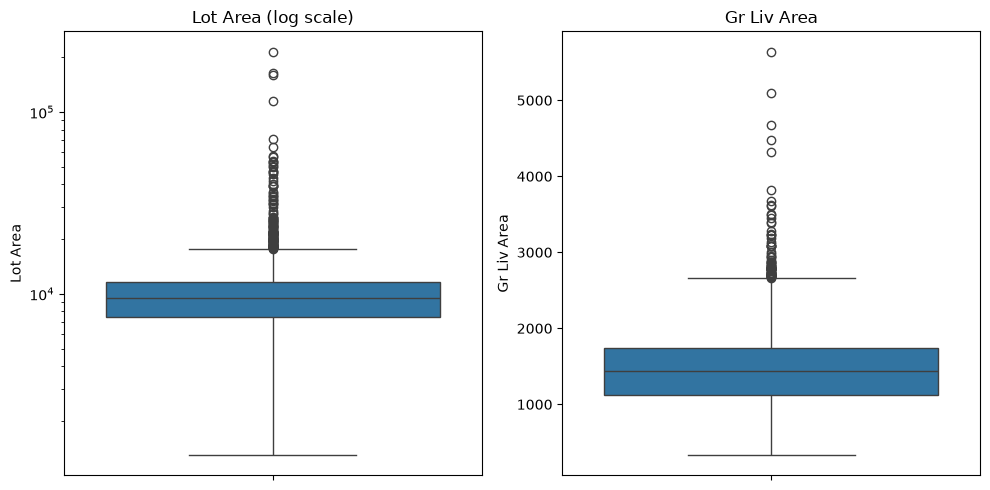

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
for ax, col in zip(axes, ["Lot Area", "Gr Liv Area"]):
    sns.boxplot(y=dataset[col], ax=ax)
    ax.set_title(col)

# Lot Area has extreme outliers, so a log scale makes the box visible
axes[0].set_yscale("log")
axes[0].set_title("Lot Area (log scale)")

plt.tight_layout()
plt.show()

- As described above, a few huge lots made the box of `Lot Area` almost invisible. On a log scale, the box becomes visible: the median is ~9,400 sqft, but the largest lot has 215,245 sqft (127 outliers by the IQR rule).
- The largest outliers of `Gr Liv Area` (> 4,000 sqft) are analyzed in Section 3.4.1 (linear regression).

## Price classes for Lab 2

In Lab 2, house prices will be predicted as 6 classes. We check how many houses fall into each class.

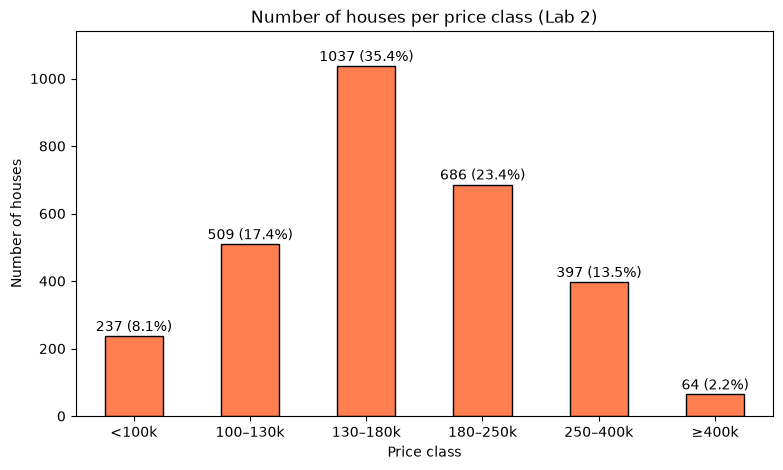

In [19]:
# The 6 price classes used for classification in Lab 2
bins = [0, 100000, 130000, 180000, 250000, 400000, np.inf]
labels = ["<100k", "100–130k", "130–180k", "180–250k", "250–400k", "≥400k"]

price_class = pd.cut(dataset["SalePrice"], bins=bins, labels=labels, right=False)
counts = price_class.value_counts().reindex(labels)

plt.figure(figsize=(9, 5))
ax = counts.plot(kind="bar", color="coral", edgecolor="black")
for i, n in enumerate(counts):
    ax.text(i, n + 15, f"{n} ({n / len(dataset):.1%})", ha="center")
plt.title("Number of houses per price class (Lab 2)")
plt.xlabel("Price class")
plt.ylabel("Number of houses")
plt.xticks(rotation=0)
plt.ylim(0, counts.max() * 1.1)
plt.show()

**Interpretation**

The classes are strongly imbalanced: 35.4% of the houses are in the 130–180k class, but only 64 houses (2.2%) cost at least $400,000. For the classification in Lab 2, a **stratified** train-test split is needed, and the smallest class will likely have the lowest recall and F1.